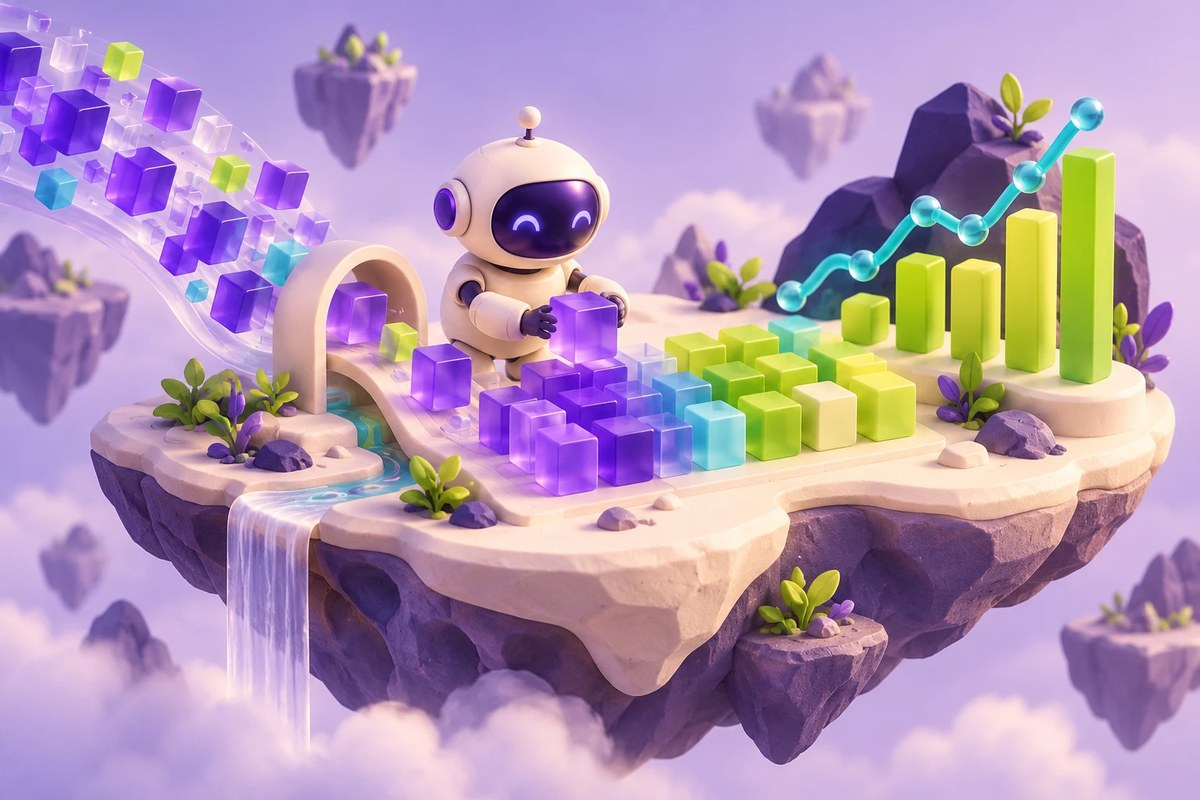

AI PATH · Python для машинного обучения · Урок 024

# Матрицы, функции и численный поиск экстремумов

Размерности, обратимость и границы графического исследования.

**Архивный учебный материал.** Код и сохранённые результаты относятся к исходному ноутбуку. Оформление не означает новый запуск или подтверждение старых метрик. Перед выполнением проверьте зависимости и ограничения.

<a id="ai-024-goal"></a>
## Что вы разберёте

Проверять смысл матричных операций и отличать приближение на сетке от аналитического решения.

### Перед началом

- Функции Python и циклы
- Матрицы и производная на базовом уровне

### Что понадобится

- NumPy и Matplotlib с поддержкой трёхмерных осей
- IPython для встроенного вывода графиков; внешние файлы не используются

## Навигация по уроку

- [Цель и подготовка](#ai-024-goal)
- [Карта урока](#ai-024-map)
- [Совместимость матриц](#ai-024-section-01)
- [Размах и обратная матрица](#ai-024-section-02)
- [Коммутативность как эксперимент](#ai-024-section-03)
- [Поверхность и экстремумы](#ai-024-section-04)
- [Формула и код](#ai-024-section-05)
- [Одномерные функции](#ai-024-section-06)
- [Проверьте понимание](#ai-024-practice)
- [Источники и ограничения](#ai-024-provenance)

<a id="ai-024-map"></a>
## Карта урока

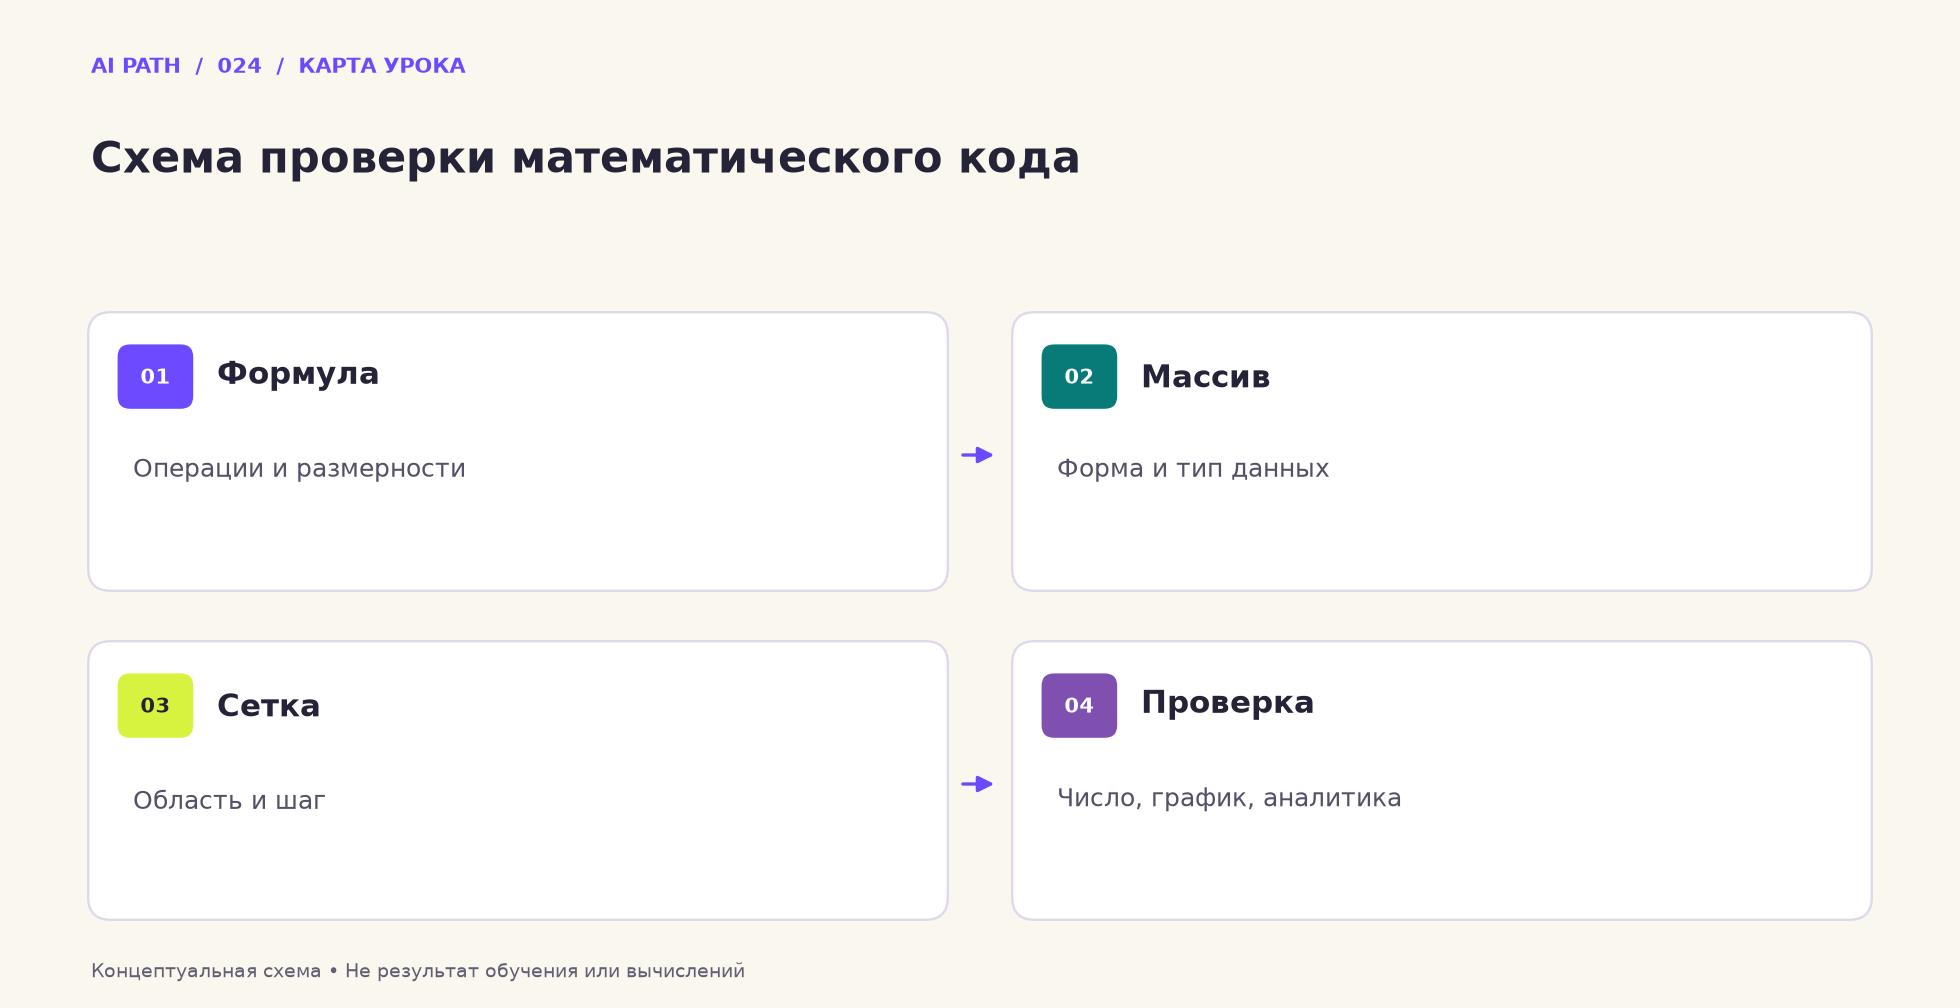

Схема показывает последовательность идей. Она не содержит результатов нового обучения или вычислений.

1. **Формула** — Операции и размерности
2. **Массив** — Форма и тип данных
3. **Сетка** — Область и шаг
4. **Проверка** — Число, график, аналитика

<a href="https://colab.research.google.com/github/safal207/hello-world/blob/master/%D0%A1%D0%B0%D1%84%D0%BE%D0%BD%D0%BE%D0%B2_%D0%90_%D0%90_%D0%9C%D0%B0%D1%82%D1%80%D0%B8%D1%86%D1%8B_%D0%B8_%D1%84%D1%83%D0%BD%D0%BA%D1%86%D0%B8%D0%B8%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Light**

In [ ]:
import numpy as np 

<a id="ai-024-section-01"></a>
## 01 · Совместимость матриц

До умножения выпишите размерности входов и ожидаемую форму результата.

_Далее — исходные ячейки учебного материала._

## **Задача 1**

Напишите функцию умножения трёх матриц

In [ ]:
def prod_matrix(mat1, mat2, mat3):
  sh1 = mat1.shape
  sh2 = mat2.shape
#Если кол-во столбцов первой матрицы не равно кол-ву столбцов  второй
  if (sh1[1] != sh2[0]): 
    return np.array([])
 #То выводим пустую матрицу 
  
  #Произведем матричное умножение
  mat_res_1 = mat1.dot(mat2)

#Если количество стобцов не равно количеству строк третей матрицы
  if (mat_res_1.shape[1] != mat3.shape[0]):
#то выводим пустую матрицу
    return np.array([]) 
  
  mat_res_2 = mat_res_1.dot(mat3)

  return mat_res_2


In [ ]:
mat1 = np.array([[0, 1, 2], [1, 2, 3], [3, 2, 1], [2, 1, 3]]) 
mat2 = np.array([[0, 1, 2, 3], [1, 2, 3, 4], [4, 3, 2, 1]]) 
mat3 = np.array([[0, 1, 2, 3, 4], [1, 2, 3, 4, 5], [5, 4, 3, 2, 1], [2, 2, 1, 2, 2]])

print(mat1, '\n')
print(mat2, '\n')
print(mat3, '\n')
print(prod_matrix(mat1, mat2, mat3))

[[0 1 2]
 [1 2 3]
 [3 2 1]
 [2 1 3]] 

[[0 1 2 3]
 [1 2 3 4]
 [4 3 2 1]] 

[[0 1 2 3 4]
 [1 2 3 4 5]
 [5 4 3 2 1]
 [2 2 1 2 2]] 

[[ 55  65  69  85  95]
 [112 126 126 154 168]
 [116 118 102 122 124]
 [104 117 117 143 156]]


<a id="ai-024-section-02"></a>
## 02 · Размах и обратная матрица

Проверьте условия существования обратной матрицы для произведения A и Aᵀ.

_Далее — исходные ячейки учебного материала._

## **Задача 2**

Напишите функцию, которая считает разницу между максимальным и минимальным элементами матрицы

In [ ]:
def mat_val(mat_):
  return mat_.max() - mat_.min()

In [ ]:
mat = np.random.randint(0,30,(2,3))
print(mat)
print('Разница между максимальными и минимальными элументами', mat_val(mat))

[[ 3  4  1]
 [ 1 22  9]]
Разница между максимальными и минимальными элументами 21


## **Задача 3**

Напишите функцию, которая
- умножает матрицу на транспорированную матрицу
- получает обратную матрицу от результата

In [ ]:
def tran_mat(mat):
  print('Матрица\n', mat)
  tranM = mat.T
  print('Транспорированнная матрица \n', tranM)
  #умножаем матрицу на транспорированную матрицу
  umnoz = mat.dot(tranM)
  print('Результат перемножения\n', umnoz)
  #Подучаем обратную матрицу от результата
  inv_mat = np.linalg.inv(umnoz)
  print('Обратная матрица\n', inv_mat)
  return



In [ ]:
tran_mat(mat)

Матрица
 [[ 3  4  1]
 [ 1 22  9]]
Транспорированнная матрица 
 [[ 3  1]
 [ 4 22]
 [ 1  9]]
Результат перемножения
 [[ 26 100]
 [100 566]]
Обратная матрица
 [[ 0.12001696 -0.02120441]
 [-0.02120441  0.00551315]]


<a id="ai-024-section-03"></a>
## 03 · Коммутативность как эксперимент

Случайные примеры иллюстрируют поведение, но не заменяют доказательство.

_Далее — исходные ячейки учебного материала._

## **Задача 4** 

Напишите функцию, которая получает на вход пару матриц и проверяет закон коммутативности умножения, то есть свойства $A*B=B*A$, возвращая ```1``` в случае подтверждения и ```0``` в противном случае. Поставьте ```1000``` экспериментов для случайных целочисленных матриц размера ```(5,5)``` элементов, которые принадлежат отрезку ```[-5,5]```, и найдите количество успешных срабатываний.

In [ ]:
def mat_com(mat1, mat2):
  mat_res1 = mat1.dot(mat2)
  mat_res2 = mat2.dot(mat1)
  if (mat_res1 == mat_res2).all():
    return 1
  else:
    return 0  

In [ ]:
res = 0
for j in range(10):
  for i in range(1000):
    mat1 = np.random.randint(-5, 5, (5,5))
    mat2 = np.random.randint(-5, 5, (5,5))
    res = res + mat_com(mat1, mat2)
  print('Количество коммутативных матриц в цике', res)  


Количество коммутативных матриц в цике 0
Количество коммутативных матриц в цике 0
Количество коммутативных матриц в цике 0
Количество коммутативных матриц в цике 0
Количество коммутативных матриц в цике 0
Количество коммутативных матриц в цике 0
Количество коммутативных матриц в цике 0
Количество коммутативных матриц в цике 0
Количество коммутативных матриц в цике 0
Количество коммутативных матриц в цике 0


<a id="ai-024-section-04"></a>
## 04 · Поверхность и экстремумы

Сетка ограничивает область поиска; различайте локальные точки и минимум на выбранном прямоугольнике.

_Далее — исходные ячейки учебного материала._

## **Задача 5**

Напишите функцию, которая находит все экстремумы двумерной функции z = x * x * sin(y), а также:

a) Возвращает листы с координатами двумерных точек - 4 листа - локальный и глобальный минимум и максимум.

b) Выводит график такой функции.

In [ ]:
# Подключаем библиотеки для отображения 3d поверхностей
import matplotlib.pyplot as plt 
import pylab, math
from mpl_toolkits.mplot3d import Axes3D
%matplotlib inline

In [ ]:
# Функция x * x * sin (y)
def x2_sin(x, y):
  xgrid, ygrid = np.meshgrid(x, y)
  zgrid = xgrid **2 * np.sin(ygrid) 
  return xgrid, ygrid, zgrid

# Поиск экстремумов
def find_extremums(f,x,y):
  # Вычислим функцию
  xgrid, ygrid, zgrid = f(x,y)

  # Пустые листы для экстремумов
  local_mins = []  # Локальные минимумы
  local_maxs = []  # Локальные максимумы
  global_min = []  # Глобальный минимум
  global_max = []  # Глобальный максимум

  # Минимальное и максимальное значение y
  min_z = round(np.amin(zgrid),5) # Округляем до 5го знака
  max_z = round(np.amax(zgrid),5) # Округляем до 5го знака
  zi, zj = zgrid.shape

  # Проходим во всем точкам
  for i in range(zi):
    for j in range(zj):
      # Если точка равна минимуму y
      # То это глобальный минимум
      if (round(zgrid[i,j],5) == min_z):
        global_min.append([xgrid[0,j], ygrid[i,0],zgrid[i,j]]) # Заносим координату в список минимумов
    
      # Если точка равна максимуму y
      # То это глобальный максимум
      if (round(zgrid[i,j],5) == max_z):
        global_max.append([xgrid[0,j], ygrid[i,0],zgrid[i,j]]) # Заносим координату в список максимумов

      # Если это не первая и не последняя точка
      # (в них не можем считать локальные минимум и максимум)
      if (i > 0 and i < zi-1 and j > 0 and j < zj-1):
        # Если точка меньше, чем соседние
        if (zgrid[i-1,j-1] > zgrid[i,j] 
            and zgrid[i+1, j+1] > zgrid[i,j] 
            and zgrid[i+1, j-1] > zgrid[i,j] 
            and zgrid[i-1, j+1] > zgrid[i,j]
            # И не является глобальным минимумом 
            and round(zgrid[i,j],5) != min_z):
          local_mins.append([xgrid[0,j], ygrid[i,0],zgrid[i,j]]) # То это локальный минимум (по всем направлениям)

        # Если точка больше, чем соседние
        if (zgrid[i-1,j-1] < zgrid[i,j] 
            and zgrid[i+1, j+1] < zgrid[i,j] 
            and zgrid[i+1, j-1] < zgrid[i,j] 
            and zgrid[i-1, j+1] < zgrid[i,j]
            #И не является глобальным максимумом 
            and round(zgrid[i,j],5) != max_z):
          local_maxs.append([xgrid[0,j], ygrid[i,0],zgrid[i,j]]) # То это локальный максимум (по всем направлениям)

  return local_mins, local_maxs, global_min, global_max

# Функция для вывода точек
def plot_points(points, axes, marker='ro'):
  if len(points) > 0: # Проверка на пустой список
    coords = np.transpose(np.array(points)) # Транспонируем для получения массива из трех координат
    axes.plot(coords[0], coords[1], coords[2], marker, markersize=5, alpha=1, zorder=99 )  
    return coords
  else:
    return np.array([])

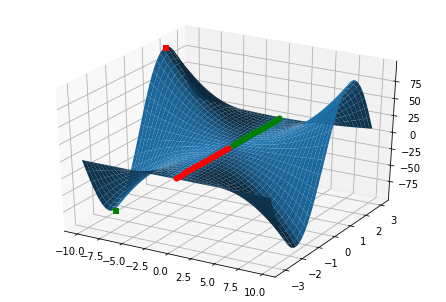

Локальные минимумы
[[-3.552713678800501e-14, 0.15840734641020981, 1.9910305772249947e-28], [-3.552713678800501e-14, 0.2584073464102099, 3.2253821610570153e-28], [-3.552713678800501e-14, 0.35840734641021, 4.427506792505347e-28], [-3.552713678800501e-14, 0.4584073464102101, 5.585393239622128e-28], [-3.552713678800501e-14, 0.5584073464102102, 6.68747228377414e-28], [-3.552713678800501e-14, 0.6584073464102103, 7.722732315451114e-28], [-3.552713678800501e-14, 0.7584073464102103, 8.680829358628002e-28], [-3.552713678800501e-14, 0.8584073464102104, 9.552190424354155e-28], [-3.552713678800501e-14, 0.9584073464102101, 1.0328109160894509e-27], [-3.552713678800501e-14, 1.0584073464102106, 1.1000832844718194e-27], [-3.552713678800501e-14, 1.1584073464102111, 1.1563639843149323e-27], [-3.552713678800501e-14, 1.2584073464102108, 1.2010906774698827e-27], [-3.552713678800501e-14, 1.3584073464102104, 1.2338164696033459e-27], [-3.552713678800501e-14, 1.458407346410211, 1.2542143754180334e-27], [-3.55271

In [ ]:
# Выводим поверхность z = x * x * sin(y)
fig = pylab.figure()
axes = Axes3D(fig)
y = np.arange (-math.pi, math.pi, 0.1)
x = np.arange (-10, 10, 0.1)
xgrid, ygrid, zgrid = x2_sin(x,y)
axes.plot_surface(xgrid, ygrid, zgrid)

# Получаем экстремумы
local_mins, local_maxs, global_min, global_max = find_extremums(x2_sin,x,y)

# Выводим точки
mins = plot_points(local_mins, axes, 'go') 
maxs = plot_points(local_maxs, axes, 'ro')
gmin = plot_points(global_min, axes, 'gs')
gmax = plot_points(global_max, axes, 'rs')
pylab.show()

# Выводим списки всех точек
print("Локальные минимумы",local_mins,sep = '\n')
print("Локальные максимумы",local_maxs,sep = '\n')
print("Глобальный минимум",global_min,sep = '\n') 
print("Глобальный максимум",global_max,sep = '\n')

# **PRO**


<a id="ai-024-section-05"></a>
## 05 · Формула и код

Сравните матрично-векторное произведение с поэлементным умножением и broadcasting.

_Далее — исходные ячейки учебного материала._

## **Задача 1**

Напишите код, который вычисляет значение следующей математической функции в зависимости от переменной х, где х - вектор

$F(x) = \frac{1}{25}AA^Tx + Bx + 5$

* Создайте матрицы A и B размера 4 на 4, состоящие из случайных целых чисел в интервале от 1 до 10 (используйте соответствующую функцию модуля np.random)
* Создайте вектора х  размера 4, состоящие из случайных целых чисел в интервале от 1 до 5

In [ ]:
a_mat = np.random.randint(1, 10, (4, 4))
b_mat = np.random.randint(1, 10, (4, 4))
x = np.random.randint(1, 5, 4)
print('Матрица a\n',a_mat)
print('Матрица b\n',b_mat)
print('Матрица x\n',x)


Матрица a
 [[1 7 3 8]
 [8 1 5 1]
 [9 5 6 9]
 [3 8 6 6]]
Матрица b
 [[6 9 7 4]
 [2 4 8 1]
 [5 1 9 6]
 [9 6 9 5]]
Матрица x
 [2 1 1 4]


In [ ]:
res = 1/25 * a_mat.dot(a_mat.T) * x + b_mat * x + 5
print('Результат функции\n',res)

Результат функции
 [[26.84 15.52 17.36 41.  ]
 [12.04 12.64 17.64 19.88]
 [25.72 10.64 22.92 54.12]
 [33.   13.72 20.28 48.2 ]]


<a id="ai-024-section-06"></a>
## 06 · Одномерные функции

Проследите шаг сетки, знаки функции и границы индексов при поиске корней и экстремумов.

_Далее — исходные ячейки учебного материала._

##**Задача 2**

Напишите и отобразите функцию y = x * x * x/12 + x * (x-15) - 72 на отрезке -10; 10

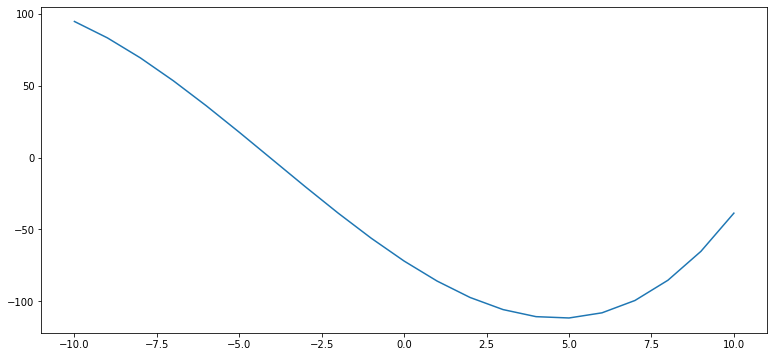

In [ ]:
def f2(x):
  y =  x * x * x/12 + x * (x-15) - 72
  return y


x = np.array([i for i in range(-10,11,1)])
plt.figure(figsize=(13,6))
plt.plot(x, f2(x))
plt.show()




##**Задача 3**

Отобразите ту же функцию на отрезке -10; 10, но с шагом 0.1 по оси x

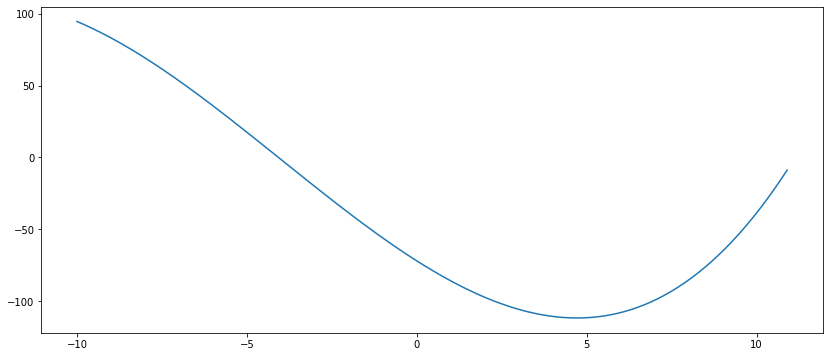

In [ ]:
x = np.array([i for i in np.arange(-10, 11, 0.1)])
plt.figure(figsize=(14,6))
plt.plot(x,f2(x))
plt.show()

##**Задача 4**

Напишите функцию, которая находит все точки пересечения нуля заданной одномерной математической функции и отображает их на графике функции красными кругами

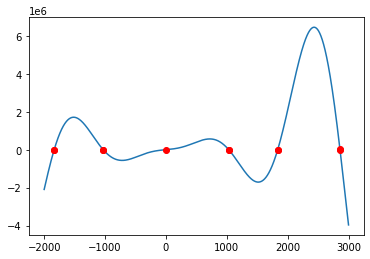

In [ ]:
# Функция
def f3(x):
  y = x*x*np.sin(x/300) + 300*x
  return y

# Функция, которая выводит график функции и отмечает точки пересечения с 0
def plot_func(f, a, b):
  x = np.array([i for i in range(a,b)])
  y = [f(i) for i in x]
  zero = []
  for i in range(len(y)):
    if i > 0 and i < len(y)-1:
      if(y[i-1] > 0 and y[i+1]) < 0:
        zero.append(i)
      if (y[i-1] < 0 and y[i+1]) > 0:
        zero.append(i)

  plt.plot(x, y)
  plt.plot([x[i] for i in zero], [y[i] for i in zero], 'ro')
  plt.show()

plot_func(f3,-2000,3000)

##**Задача 5**

Напишите функцию, которая находит точку, где функция растёт быстрее всего и медленнее всего и отображает на графике функции эти точки зелёным и красным кругом

[1202.27130472 1200.77819128 1199.26267805 1197.72490394 1196.16500817
 1194.58313027 1192.97941007 1191.35398769 1189.70700357 1188.03859842
 1186.34891325 1184.63808934 1182.90626828 1181.15359191 1179.38020236
 1177.586242   1175.7718535  1173.93717978 1172.082364   1170.2075496 ]


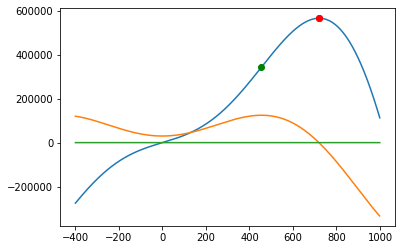

In [ ]:
def f4(x):
  y = x*x*np.sin(x/300) + 300*x
  return y

def plot_func_dep(f, a, b):
  x = np.array([i for i in range(a,b)])
  len_x = x.shape[0]

  # Производная
  df = np.array([f(x[i+1]) - f(x[i]) for i in range(len_x-1)])
  print(df[:20])
  # Значения нашей функции
  y = [f(i) for i in x]

  # Максимальное значение производной - там функция растет быстрее всего
  df_max = np.max(df)

  # Массивы для записи точек
  depr_max = []
  depr_zero = []

  # Проходимся циклом по значениям производной и записываем 
  for i in range(len(y)-1):
    if df[i] == df_max:
      depr_max.append(i)
    if (df[i-1] > 0 and df[i+1]) < 0:
       depr_zero.append(i)

  # Строим график
  plt.plot(x, y)
  plt.plot(x[:-1], df*100)
  plt.plot(x, np.array([0 for i in range(a,b)]))
  plt.plot([x[i] for i in depr_max], [y[i] for i in depr_max], 'go')  
  plt.plot([x[i] for i in depr_zero], [y[i] for i in depr_zero], 'ro')
  plt.show()

plot_func_dep(f4, -400, 1000)

<a id="ai-024-practice"></a>
## Проверьте понимание

1. Какова форма результата ячейки 22 и совпадает ли она с формулой задания?
2. Когда A·Aᵀ оказывается необратимой?
3. Какие соседние точки проверяет поиск экстремумов в ячейке 17?

### Один самостоятельный эксперимент

В отдельной копии сравните сеточный поиск минимума квадратичной функции с её известным аналитическим минимумом при двух шагах.

**Критерий успеха:** Указаны область поиска, оба шага и ошибка координаты; результат не объявлен глобальным вне этой области.

<a id="ai-024-provenance"></a>
## Источники и ограничения

[Исходный ноутбук и его авторские материалы](https://github.com/safal207/students/blob/d848e04c8f8d6e3e8e42ce15fbd98c00612e0e17/MatrixAndFunctions/%D0%A1%D0%B0%D1%84%D0%BE%D0%BD%D0%BE%D0%B2_%D0%90_%D0%90_%D0%9C%D0%B0%D1%82%D1%80%D0%B8%D1%86%D1%8B_%D0%B8_%D1%84%D1%83%D0%BD%D0%BA%D1%86%D0%B8%D0%B8%22.ipynb) · репозиторий `safal207/students`.

Исходные подписи, ссылки, авторство, код, изображения и аудио сохранены. Длинные текстовые выводы могут быть сокращены с указанием источника. Архивные результаты не пересчитывались.

### Перед новым запуском

- В ячейке 22 умножение на x выполняется через *, поэтому результат отличается от матрично-векторной формулы.
- Условия смены знака в ячейках 28 и 30 требуют исправления; обращение к df[i+1] в конце цикла может выйти за границу.
- Обратная матрица вычисляется без обработки вырожденности; случайные данные не фиксируются seed.
- Поиск поверхности использует ограниченную сетку и неполную проверку соседей; запуск и новые результаты не выполнялись.

**Иллюстрации:** обложка направления AI PATH; карта урока подготовлена по содержимому исходных ячеек.